# Datos de Giovanni

Carga de los seis CSV de `data/giovanni` como DataFrames de pandas, uno por variable. Los valores de relleno se convierten en `NaN`; no se convierten unidades.

In [566]:
import pandas as pd
from pathlib import Path

CARPETA_DATOS = Path.cwd() / "data" / "giovanni"


def cargar_giovanni(ruta):
    lineas = ruta.read_text(encoding="utf-8-sig").splitlines()
    inicio = next(
        i for i, linea in enumerate(lineas)
        if linea.strip().lower().startswith("time")
    )
    rellenos = [
        float(linea.split(",", 1)[1])
        for linea in lineas[:inicio]
        if linea.startswith("Fill Value")
    ]

    df = pd.read_csv(
        ruta,
        skiprows=inicio,
        encoding="utf-8-sig",
        skipinitialspace=True,
        na_values=rellenos or None,
    )
    df.columns = ["fecha", "valor"]
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df


precipitaciones = cargar_giovanni(CARPETA_DATOS / "Precipitaciones-GPM_3IMERGM-Giovanni.csv")
temperatura_aire = cargar_giovanni(CARPETA_DATOS / "Temperatura-del-aire-M2IMNXLFO-Giovanni.csv")
velocidad_viento = cargar_giovanni(CARPETA_DATOS / "Velocidad-del-viento-M2IMNXLFO-Giovanni.csv")
temperatura_suelo = cargar_giovanni(CARPETA_DATOS / "Temperatura-del-suelo-GLDAS_NOAH025_M-Giovanni.csv")
humedad_especifica = cargar_giovanni(CARPETA_DATOS / "Humedad-especifica-a-2-metros-M2TMNXSLV-Giovanni.csv")
espesor_aerosoles = cargar_giovanni(CARPETA_DATOS / "Espesor-optico-de-aerosoles-M2TMNXAER-Giovanni.csv")

datos = {
    "precipitaciones": precipitaciones,
    "temperatura_aire": temperatura_aire,
    "velocidad_viento": velocidad_viento,
    "temperatura_suelo": temperatura_suelo,
    "humedad_especifica": humedad_especifica,
    "espesor_aerosoles": espesor_aerosoles,
}

print(f"Datasets cargados: {len(datos)}")

Datasets cargados: 6


In [567]:
for nombre, df in datos.items():
    print(nombre, df.shape)

precipitaciones.head()

precipitaciones (249, 2)
temperatura_aire (252, 2)
velocidad_viento (252, 2)
temperatura_suelo (252, 2)
humedad_especifica (252, 2)
espesor_aerosoles (252, 2)


,fecha,valor
0,2005-01-01,0.065677
1,2005-02-01,0.043611
2,2005-03-01,0.089271
3,2005-04-01,0.096826
4,2005-05-01,0.233302


In [568]:
velocidad_viento.head()

,fecha,valor
0,2005-01-01,6.501831
1,2005-02-01,5.540147
2,2005-03-01,5.927112
3,2005-04-01,6.337231
4,2005-05-01,6.197738


In [569]:
temperatura_aire.head()

,fecha,valor
0,2005-01-01,11.517389
1,2005-02-01,13.690760
2,2005-03-01,11.191553
3,2005-04-01,9.419794
4,2005-05-01,6.621850


In [570]:

df_conaf = pd.read_csv("./data/conaf/conaf.csv")
df_conaf.head()

,año,temporada,mes,IX
0,2014,2014-2015,JULIO,0.0
1,2014,2014-2015,AGOSTO,1.0
2,2014,2014-2015,SEPTIEMBRE,0.0
3,2014,2014-2015,OCTUBRE,19.0
4,2014,2014-2015,NOVIEMBRE,61.0


In [571]:
df_conaf_comuna = pd.read_csv("./data/conaf/conaf_comuna.csv")
df_conaf_comuna.head()

,año,temporada,region,provincia,comuna,numero_incendios
0,2014,2014-2015,IX,MALLECO,ANGOL,63.0
1,2014,2014-2015,IX,MALLECO,PUREN,36.0
2,2014,2014-2015,IX,MALLECO,LOS SAUCES,68.0
3,2014,2014-2015,IX,MALLECO,RENAICO,22.0
4,2014,2014-2015,IX,MALLECO,COLLIPULLI,290.0


In [572]:
df_region_mensual = pd.read_csv('./datos_mensuales_2014_2023/region_mensual.csv')
df_region_mensual.head()

,month,region_id,region_name,temperature_2m_c,dewpoint_2m_c,specific_humidity_2m_kgkg,wind_u_10m_ms,wind_v_10m_ms,meteorologia_mensual_valid_area_pct,wind_speed_lowest_model_ms,...,soil_temperature_0_10cm_c,suelo_mensual_valid_area_pct,aod_550,aerosoles_mensual_valid_area_pct,precipitation_mm,precipitacion_mensual_valid_area_pct,temperature_monthly_peak_area_mean_c,temperature_monthly_max_c,relative_humidity_2m_pct,wind_speed_10m_ms
0,2014-01,9,La Araucan?a,16.026,6.972,0.006827,1.583,1.133,100.0,5.533,...,15.595,98.85,0.071417,100.0,75.036,100.0,34.818,40.49,62.323,3.184
1,2014-02,9,La Araucan?a,15.590,7.112,0.006798,0.834,0.851,100.0,5.155,...,15.387,98.85,0.076088,100.0,27.721,100.0,30.175,36.62,63.543,2.928
2,2014-03,9,La Araucan?a,12.966,5.811,0.006249,1.110,0.725,100.0,4.946,...,13.051,98.85,0.084697,100.0,94.426,100.0,29.191,34.39,68.342,2.781
3,2014-04,9,La Araucan?a,9.473,5.277,0.006051,0.504,0.426,100.0,4.386,...,9.636,98.85,0.061430,100.0,75.418,100.0,21.857,25.11,78.629,2.353
4,2014-05,9,La Araucan?a,7.875,5.537,0.006153,0.420,-1.376,100.0,5.190,...,7.699,98.85,0.049478,100.0,195.383,100.0,17.220,21.71,86.704,2.749


In [573]:
df_region_mensual.drop(columns=['region_name'])


,month,region_id,temperature_2m_c,dewpoint_2m_c,specific_humidity_2m_kgkg,wind_u_10m_ms,wind_v_10m_ms,meteorologia_mensual_valid_area_pct,wind_speed_lowest_model_ms,viento_nivel_modelo_mensual_valid_area_pct,...,soil_temperature_0_10cm_c,suelo_mensual_valid_area_pct,aod_550,aerosoles_mensual_valid_area_pct,precipitation_mm,precipitacion_mensual_valid_area_pct,temperature_monthly_peak_area_mean_c,temperature_monthly_max_c,relative_humidity_2m_pct,wind_speed_10m_ms
0,2014-01,9,16.026,6.972,0.006827,1.583,1.133,100.0,5.533,100.0,...,15.595,98.85,0.071417,100.0,75.036,100.0,34.818,40.49,62.323,3.184
1,2014-02,9,15.590,7.112,0.006798,0.834,0.851,100.0,5.155,100.0,...,15.387,98.85,0.076088,100.0,27.721,100.0,30.175,36.62,63.543,2.928
2,2014-03,9,12.966,5.811,0.006249,1.110,0.725,100.0,4.946,100.0,...,13.051,98.85,0.084697,100.0,94.426,100.0,29.191,34.39,68.342,2.781
3,2014-04,9,9.473,5.277,0.006051,0.504,0.426,100.0,4.386,100.0,...,9.636,98.85,0.061430,100.0,75.418,100.0,21.857,25.11,78.629,2.353
4,2014-05,9,7.875,5.537,0.006153,0.420,-1.376,100.0,5.190,100.0,...,7.699,98.85,0.049478,100.0,195.383,100.0,17.220,21.71,86.704,2.749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,2023-08,9,5.743,2.492,0.004989,1.065,-0.830,100.0,4.938,100.0,...,4.551,98.85,0.054195,100.0,231.019,100.0,17.541,21.57,82.245,2.721
116,2023-09,9,6.404,3.051,0.005149,1.158,-0.787,100.0,5.373,100.0,...,5.051,98.85,0.070600,100.0,190.836,100.0,21.701,26.09,81.999,3.010
117,2023-10,9,8.789,3.729,0.005348,1.352,0.694,100.0,5.001,100.0,...,7.376,98.85,0.100393,100.0,55.634,100.0,23.908,31.66,74.800,2.903
118,2023-11,9,10.433,4.506,0.005667,1.878,-0.035,100.0,5.381,100.0,...,9.055,98.85,0.082945,100.0,77.564,100.0,27.756,33.97,71.516,3.141


In [574]:
df_conaf.head()

,año,temporada,mes,IX
0,2014,2014-2015,JULIO,0.0
1,2014,2014-2015,AGOSTO,1.0
2,2014,2014-2015,SEPTIEMBRE,0.0
3,2014,2014-2015,OCTUBRE,19.0
4,2014,2014-2015,NOVIEMBRE,61.0


In [575]:
df_region.columns

Index(['region_id', 'temperature_2m_c', 'dewpoint_2m_c',
       'specific_humidity_2m_kgkg', 'wind_u_10m_ms', 'wind_v_10m_ms',
       'meteorologia_mensual_valid_area_pct', 'wind_speed_lowest_model_ms',
       'viento_nivel_modelo_mensual_valid_area_pct',
       'soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c',
       'suelo_mensual_valid_area_pct', 'aod_550',
       'aerosoles_mensual_valid_area_pct', 'precipitation_mm',
       'precipitacion_mensual_valid_area_pct',
       'temperature_monthly_peak_area_mean_c', 'temperature_monthly_max_c',
       'relative_humidity_2m_pct', 'wind_speed_10m_ms', 'mes', 'año', 'fecha'],
      dtype='str')

In [576]:
df_region = df_region.iloc[6:-6, :]



In [577]:
df_region.head()

,region_id,temperature_2m_c,dewpoint_2m_c,specific_humidity_2m_kgkg,wind_u_10m_ms,wind_v_10m_ms,meteorologia_mensual_valid_area_pct,wind_speed_lowest_model_ms,viento_nivel_modelo_mensual_valid_area_pct,soil_moisture_0_10cm_kgm2,...,aerosoles_mensual_valid_area_pct,precipitation_mm,precipitacion_mensual_valid_area_pct,temperature_monthly_peak_area_mean_c,temperature_monthly_max_c,relative_humidity_2m_pct,wind_speed_10m_ms,mes,año,fecha
6,9,4.941,3.239,0.005199,0.266,-1.254,100.0,5.113,100.0,34.891,...,100.0,263.345,100.0,17.015,20.92,89.935,2.745,JULIO,2014,2014-07-01
7,9,6.650,4.043,0.005546,0.423,-0.960,100.0,4.998,100.0,36.106,...,100.0,184.317,100.0,19.305,23.68,85.265,2.706,AGOSTO,2014,2014-08-01
8,9,7.089,4.680,0.005717,0.941,-1.298,100.0,5.106,100.0,33.986,...,100.0,168.875,100.0,17.541,22.76,86.468,2.855,SEPTIEMBRE,2014,2014-09-01
9,9,9.645,5.959,0.006315,1.159,0.056,100.0,4.692,100.0,31.925,...,100.0,61.022,100.0,22.407,28.12,80.461,2.652,OCTUBRE,2014,2014-10-01
10,9,10.572,6.242,0.006386,1.231,1.084,100.0,4.839,100.0,28.159,...,100.0,22.101,100.0,24.939,33.22,77.462,2.808,NOVIEMBRE,2014,2014-11-01


In [578]:
print("CONAF:", df_conaf.columns.tolist())
print("REGIÓN:", df_region.columns.tolist())


CONAF: ['año', 'temporada', 'mes', 'IX']
REGIÓN: ['region_id', 'temperature_2m_c', 'dewpoint_2m_c', 'specific_humidity_2m_kgkg', 'wind_u_10m_ms', 'wind_v_10m_ms', 'meteorologia_mensual_valid_area_pct', 'wind_speed_lowest_model_ms', 'viento_nivel_modelo_mensual_valid_area_pct', 'soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c', 'suelo_mensual_valid_area_pct', 'aod_550', 'aerosoles_mensual_valid_area_pct', 'precipitation_mm', 'precipitacion_mensual_valid_area_pct', 'temperature_monthly_peak_area_mean_c', 'temperature_monthly_max_c', 'relative_humidity_2m_pct', 'wind_speed_10m_ms', 'mes', 'año', 'fecha']


In [579]:
MESES = {
    "ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6,
    "JULIO": 7, "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10,
    "NOVIEMBRE": 11, "DICIEMBRE": 12,
}

df_conaf = pd.read_csv("./data/conaf/conaf.csv")
df_region = pd.read_csv("./definitivo_region_mensual/region_mensual.csv")

# CONAF: año calendario real
mes_conaf = df_conaf["mes"].str.upper().str.strip().map(MESES)
inicio = df_conaf["temporada"].str[:4].astype(int)
anio_conaf = inicio.where(mes_conaf >= 7, inicio + 1)
df_conaf["fecha"] = pd.to_datetime(
    dict(year=anio_conaf, month=mes_conaf, day=1)
)

# NASA: año calendario directo
mes_region = df_region["mes"].str.upper().str.strip().map(MESES)
df_region["fecha"] = pd.to_datetime(
    dict(year=df_region["año"].astype(int), month=mes_region, day=1)
)

# Unión por la fecha real, no por año+mes crudo
df_fusionado = pd.merge(
    df_conaf,
    df_region,
    on="fecha",
    how="outer",
    validate="one_to_one",
    sort=True,
)

In [580]:
df_fusionado = df_fusionado.dropna().reset_index(drop=True)

In [581]:
# Exportar df_conaf a un archivo CSV
df_fusionado.to_csv('definitivo.csv', index=False)


In [582]:
df_fusionado.columns

Index(['año_x', 'temporada', 'mes_x', 'IX', 'fecha', 'region_id',
       'temperature_2m_c', 'dewpoint_2m_c', 'specific_humidity_2m_kgkg',
       'wind_u_10m_ms', 'wind_v_10m_ms', 'meteorologia_mensual_valid_area_pct',
       'wind_speed_lowest_model_ms',
       'viento_nivel_modelo_mensual_valid_area_pct',
       'soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c',
       'suelo_mensual_valid_area_pct', 'aod_550',
       'aerosoles_mensual_valid_area_pct', 'precipitation_mm',
       'precipitacion_mensual_valid_area_pct',
       'temperature_monthly_peak_area_mean_c', 'temperature_monthly_max_c',
       'relative_humidity_2m_pct', 'wind_speed_10m_ms', 'mes_y', 'año_y'],
      dtype='str')

Filas usadas: 114 de 114


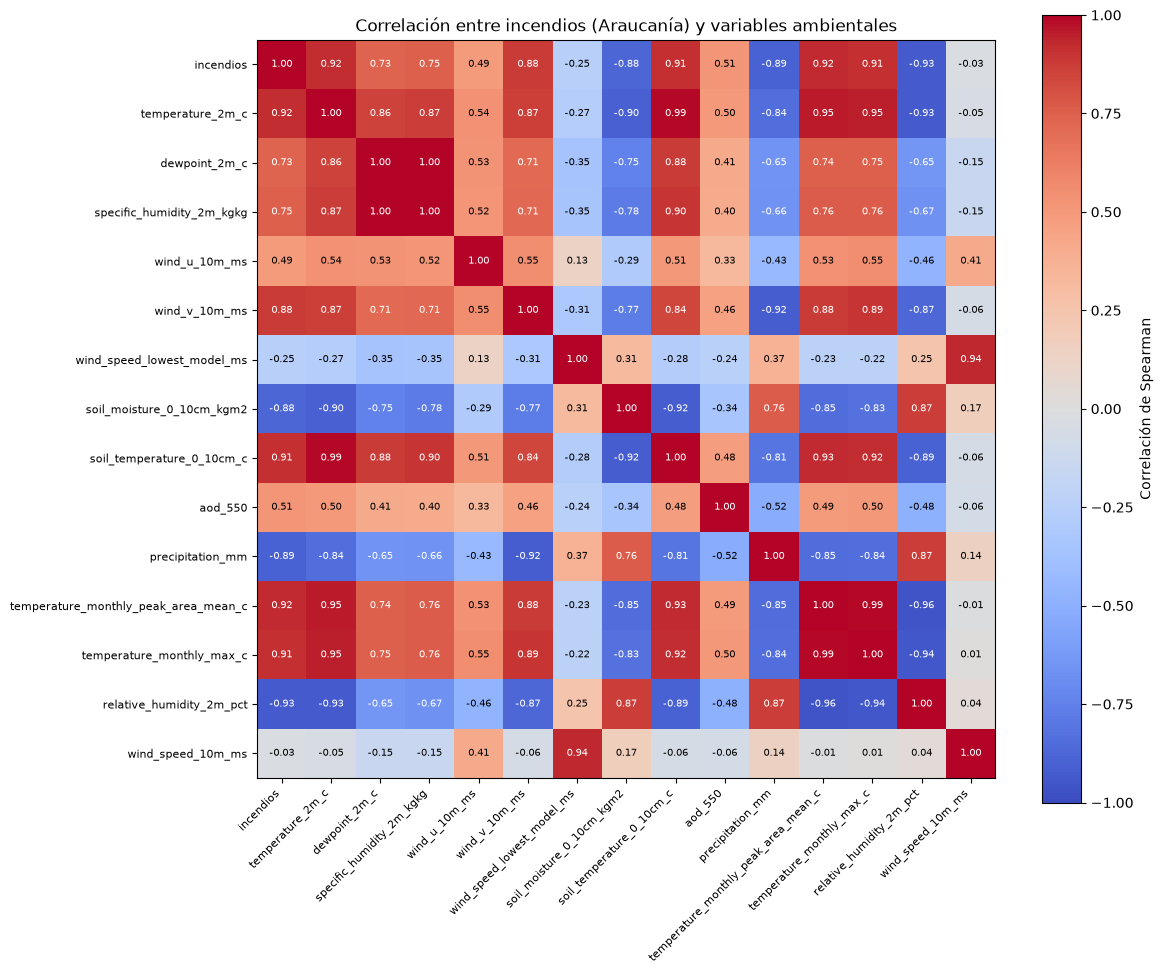

relative_humidity_2m_pct               -0.926310
temperature_monthly_peak_area_mean_c    0.924174
temperature_2m_c                        0.917037
temperature_monthly_max_c               0.913657
soil_temperature_0_10cm_c               0.909936
precipitation_mm                       -0.893835
wind_v_10m_ms                           0.881367
soil_moisture_0_10cm_kgm2              -0.877467
specific_humidity_2m_kgkg               0.745340
dewpoint_2m_c                           0.733537
aod_550                                 0.513413
wind_u_10m_ms                           0.485961
wind_speed_lowest_model_ms             -0.252903
wind_speed_10m_ms                      -0.029554
Name: incendios, dtype: float64


In [583]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = df_fusionado.rename(columns={"IX": "incendios"})

# Variables numéricas de interés: sin columnas de tiempo, ids ni calidad de datos
excluir = {"año_x", "año_y", "mes_x", "mes_y", "temporada", "fecha", "region_id"}
cols = [
    c for c in df.columns
    if c not in excluir
    and not c.endswith("valid_area_pct")
    and pd.api.types.is_numeric_dtype(df[c])
]

# Solo filas con datos de ambos datasets (el outer merge deja NaN en los extremos)
datos = df[cols].dropna()
print(f"Filas usadas: {len(datos)} de {len(df)}")

corr = datos.corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(cols, fontsize=8)

for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "black")

fig.colorbar(im, ax=ax, label="Correlación de Spearman")
ax.set_title("Correlación entre incendios (Araucanía) y variables ambientales")
plt.tight_layout()
plt.savefig("matriz_correlacion.png", dpi=200)
plt.show()

# Ranking respecto a los incendios
print(corr["incendios"].drop("incendios").sort_values(key=abs, ascending=False))

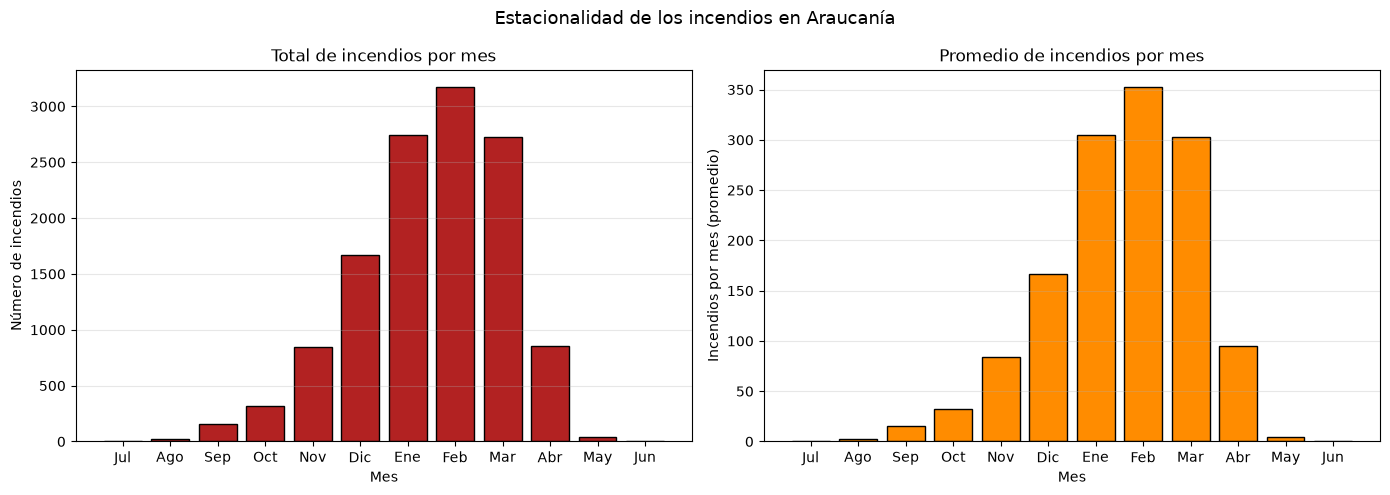

In [584]:
import pandas as pd
import matplotlib.pyplot as plt

df = df_fusionado.rename(columns={"IX": "incendios"}).copy()
df = df.dropna(subset=["incendios"])

df["mes_num"] = df["fecha"].dt.month

# Total y promedio por mes del año
total = df.groupby("mes_num")["incendios"].sum()
promedio = df.groupby("mes_num")["incendios"].mean()

# Orden de la temporada: julio a junio
orden = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
etiquetas = ["Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
             "Ene", "Feb", "Mar", "Abr", "May", "Jun"]
total = total.reindex(orden)
promedio = promedio.reindex(orden)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(etiquetas, total.values, color="firebrick", edgecolor="black")
axes[0].set_title("Total de incendios por mes")
axes[0].set_ylabel("Número de incendios")

axes[1].bar(etiquetas, promedio.values, color="darkorange", edgecolor="black")
axes[1].set_title("Promedio de incendios por mes")
axes[1].set_ylabel("Incendios por mes (promedio)")

for ax in axes:
    ax.set_xlabel("Mes")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Estacionalidad de los incendios en Araucanía", fontsize=13)
plt.tight_layout()
plt.savefig("incendios_por_mes.png", dpi=200)
plt.show()